# Fixed Income Analytics, Yield Curve Modelling & Portfolio Risk Engine

## 1. Project Introduction

Fixed-income securities expose investors to interest-rate risk because the present value of their contractual cash flows changes when market yields change. The size and distribution of those effects depend on cash-flow timing, coupon rates, maturity, and the shape of the yield curve.

A parallel yield-curve shift affects bonds according to their duration and convexity. Non-parallel movements—such as steepening, flattening, and twists—create additional risks that a single duration measure cannot fully explain. A practical risk framework therefore combines bond valuation, maturity-specific yield movements, portfolio aggregation, tail-risk estimates, and scenario analysis.

This notebook builds an educational fixed-income risk engine in Python using historical US Treasury par-yield observations from a local CSV file. It develops bond pricing and sensitivity functions, explores yield-curve movements with PCA, values a synthetic multi-maturity Treasury portfolio, and estimates risk under historical yield-change scenarios and hypothetical stress scenarios.

## 2. Objectives and Scope

The notebook currently implements the following components:

1. **Data preparation and exploration:** Load, clean, align, and visualize six Treasury par-yield series.
2. **Bond valuation:** Price regular fixed-coupon bonds from face value, coupon rate, maturity, yield to maturity, and coupon frequency.
3. **Interest-rate sensitivity:** Calculate Macaulay duration, modified duration, DV01, convexity, and compare duration-based price approximations with full repricing.
4. **Yield-curve analysis:** Interpolate observed par yields and build an illustrative spot curve from interpolated par-yield assumptions.
5. **PCA:** Identify dominant patterns in standardized historical yield changes and measure explained variance.
6. **Portfolio risk:** Aggregate market value, modified duration, and DV01 for a synthetic portfolio of 2Y, 5Y, 10Y, and 30Y bonds.
7. **Tail risk and scenario analysis:** Estimate historical-simulation VaR and Expected Shortfall from yield-change scenarios, run a rolling exception analysis, and conduct parallel and non-parallel stress tests.
8. **Model diagnostics and communication:** Apply the Kupiec proportion-of-failures test and summarize results, assumptions, and limitations.

Some capabilities that would be natural extensions—but are **not implemented in this notebook**—include market-calibrated zero-coupon bootstrapping, genuine curve-node key rate duration, parametric or Monte Carlo VaR, PCA-factor portfolio VaR, dynamic hedging, clean/dirty pricing with accrued interest, and conditional-coverage backtesting.

## 3. Research Question

How do classical duration-based measures, full bond repricing, historical yield-change scenarios, and curve-shape stress tests characterize the market risk of a synthetic Treasury portfolio?

The analysis highlights the strengths and limitations of each technique. PCA is used here to explore historical yield-curve changes; it is not yet used to generate portfolio VaR forecasts.

## 4. Methodology and Workflow

The notebook proceeds from data preparation to individual-bond valuation, interest-rate sensitivity, yield-curve interpolation and approximate bootstrapping, PCA, portfolio aggregation, historical scenario P&L, VaR and Expected Shortfall, backtesting diagnostics, stress testing, and final findings.

The portfolio is illustrative rather than a record of actual holdings. The historical P&L distribution is generated by applying observed daily changes in the corresponding par-yield series to a fixed reference portfolio and repricing the bonds. It should therefore be interpreted as a historical **scenario distribution**, not as actual realized P&L from a portfolio revalued on each historical date.

## 5. Implementation Principles

- Project-specific functions are defined within this notebook.
- Financial assumptions, rate units, and portfolio conventions are documented explicitly.
- Full repricing is used where appropriate to compare with duration-based approximations.
- Historical yield observations and hypothetical stress scenarios are distinguished from actual portfolio returns.
- In-sample estimation and rolling evaluation windows are distinguished, and backtest conclusions are kept proportionate to the tests performed.
- Outputs are interpreted in financial terms, with limitations stated rather than obscured.

## 6. Expected Outcome

The deliverable is a reproducible educational framework for fixed-income valuation and market-risk analysis. Its results demonstrate how yield movements translate into bond and portfolio value changes and how VaR, Expected Shortfall, and stress testing provide complementary views of risk. The framework is not a production valuation system: market-calibrated discount curves, more complete bond conventions, and additional validation tests remain potential extensions.


## 7. Environment Setup and Data Sources

The analysis uses a local historical US Treasury par-yield CSV file. The notebook reads the file from `data/raw/par-yield-curve-rates-1990-2023.csv`, selects six maturities, and restricts the analysis sample to observations after January 1, 2010.

The resulting sample runs from January 2010 through December 2023 in the current file. Because the input is a local snapshot, rerunning the notebook will reproduce that historical sample rather than retrieve new observations automatically. The CSV must be present at the expected relative path from the notebook's working directory.

All rates and shocks must use consistent units. The raw yield columns are in percentage points (for example, `4.25` means 4.25%); calculations requiring decimal yields divide by 100. Daily changes are converted from percentage points to basis points by multiplying differences by 100.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from sklearn.decomposition import PCA

np.set_printoptions(suppress=True, precision=6)


## 8. Data Collection — US Treasury Par-Yield Curve

### 8.1 Input File and Maturities

The notebook loads the local file `data/raw/par-yield-curve-rates-1990-2023.csv`. It selects these six Treasury par-yield maturities:

- 3-month (`3M`)
- 1-year (`1Y`)
- 2-year (`2Y`)
- 5-year (`5Y`)
- 10-year (`10Y`)
- 30-year (`30Y`)

The file contains older history, but the working dataset is filtered to dates after January 1, 2010. The current cleaned sample ends on December 29, 2023.

### 8.2 Why These Maturities?

The maturities represent short-, intermediate-, and long-term points on the term structure. Their joint movements help characterize level-like, slope-like, and curvature-like changes in yields and provide historical scenarios for the portfolio's 2Y, 5Y, 10Y, and 30Y positions.

### 8.3 Data and Unit Considerations

The quoted yields are expressed in **percentage points**, not decimal form. The original `yields` DataFrame is retained in percentage-point units for reporting. A separate `yields_decimal` DataFrame is created for calculations that require decimal yields.

Missing observations are removed so the yield series are aligned before calculating daily changes. The source values are Treasury **par yields**, not zero-coupon spot rates. Linear interpolation and the later bootstrap are explicitly approximate; they should not be interpreted as an official Treasury zero-coupon curve.


In [2]:

yields = pd.read_csv(r".\data\raw\par-yield-curve-rates-1990-2023.csv", parse_dates=['date']).set_index('date')

yields = yields.loc[:, ['3 mo', '1 yr', '2 yr', '5 yr', '10 yr', '30 yr']]

start_date = "2010-01-01"

yields = yields[yields.index>start_date]

yields = yields.rename(columns={
    '3 mo': '3M',
    '1 yr': '1Y',
    '2 yr': '2Y',
    '5 yr': '5Y',
    '10 yr': '10Y',
    '30 yr': '30Y'
})

yields.head()



,3M,1Y,2Y,5Y,10Y,30Y
date,,,,,,
2010-01-04,0.08,0.45,1.09,2.65,3.85,4.65
2010-01-05,0.07,0.41,1.01,2.56,3.77,4.59
2010-01-06,0.06,0.40,1.01,2.60,3.85,4.70
2010-01-07,0.05,0.40,1.03,2.62,3.85,4.69
2010-01-08,0.05,0.37,0.96,2.57,3.83,4.70


In [3]:

# Remove dates with missing yields
yields = yields.dropna()

# Check the cleaned dataset
print("Shape:", yields.shape)
print("\nMissing values:")
print(yields.isna().sum())

print("\nDate range:")
print(yields.index.min(), "to", yields.index.max())



yields.head()

Shape: (3502, 6)

Missing values:
3M     0
1Y     0
2Y     0
5Y     0
10Y    0
30Y    0
dtype: int64

Date range:
2010-01-04 00:00:00 to 2023-12-29 00:00:00


,3M,1Y,2Y,5Y,10Y,30Y
date,,,,,,
2010-01-04,0.08,0.45,1.09,2.65,3.85,4.65
2010-01-05,0.07,0.41,1.01,2.56,3.77,4.59
2010-01-06,0.06,0.40,1.01,2.60,3.85,4.70
2010-01-07,0.05,0.40,1.03,2.62,3.85,4.69
2010-01-08,0.05,0.37,0.96,2.57,3.83,4.70


## 8.4 Yield Units and Data Transformation

The CSV stores quoted yields in percentage points. For example, `4.25` represents 4.25%, not a decimal yield of 4.25.

For calculations that require decimal yields, divide the raw observations by 100:

$$
y_{\text{decimal}}=\frac{y_{\text{percentage points}}}{100}
$$

For example, 4.25% becomes 0.0425. We retain the original `yields` DataFrame in percentage-point units and store decimal values separately in `yields_decimal`.


In [4]:
yields_decimal = yields / 100
yields_decimal.head()

,3M,1Y,2Y,5Y,10Y,30Y
date,,,,,,
2010-01-04,0.0008,0.0045,0.0109,0.0265,0.0385,0.0465
2010-01-05,0.0007,0.0041,0.0101,0.0256,0.0377,0.0459
2010-01-06,0.0006,0.0040,0.0101,0.0260,0.0385,0.0470
2010-01-07,0.0005,0.0040,0.0103,0.0262,0.0385,0.0469
2010-01-08,0.0005,0.0037,0.0096,0.0257,0.0383,0.0470


## 8.5 Exploratory Data Analysis — Treasury Yield Curves

Before estimating risk, inspect the time series at each maturity. This shows broad rate regimes, periods of volatility, and differences between short-, intermediate-, and long-term yields.

Short-term yields often react strongly to monetary-policy expectations; longer-term yields also reflect growth and inflation expectations and the term premium. These are possible economic interpretations rather than relationships identified by this chart alone.

The time-series plot is followed by a snapshot of the latest observed curve. Together, the charts provide context for the yield-change and PCA analysis that follows.


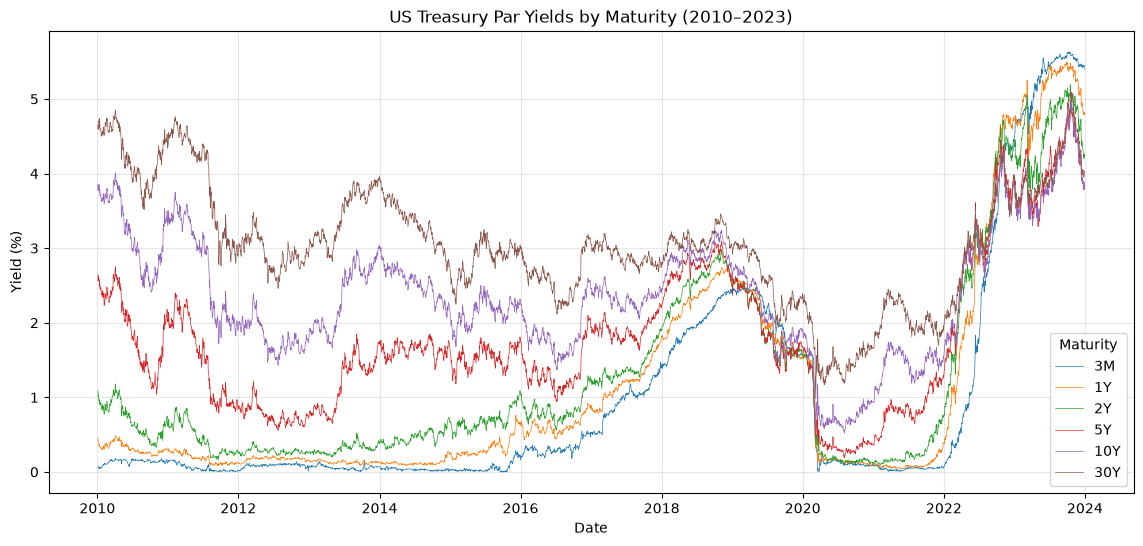

In [5]:
fig, axes = plt.subplots(figsize = (14,6))

for maturity in yields.columns:
    axes.plot(
        yields.index,
        yields[maturity],
        label = maturity,
        linewidth = 0.5
    )

axes.set_title(f"US Treasury Par Yields by Maturity ({yields.index.min().year}–{yields.index.max().year})")
axes.set_xlabel("Date")
axes.set_ylabel("Yield (%)")
axes.legend(title="Maturity")
axes.grid(True, alpha=0.3)

plt.show()


### 8.6 Latest Observed Yield Curve

A time-series chart shows how yields evolve; a yield-curve snapshot shows their relationship across maturities on one date. The snapshot uses the last available date in the CSV, so it reflects December 29, 2023 in the current data file—not the current market curve.

The curve's shape can be upward-sloping, flat, or inverted. Changes in its level and shape motivate the subsequent PCA and portfolio stress analyses.


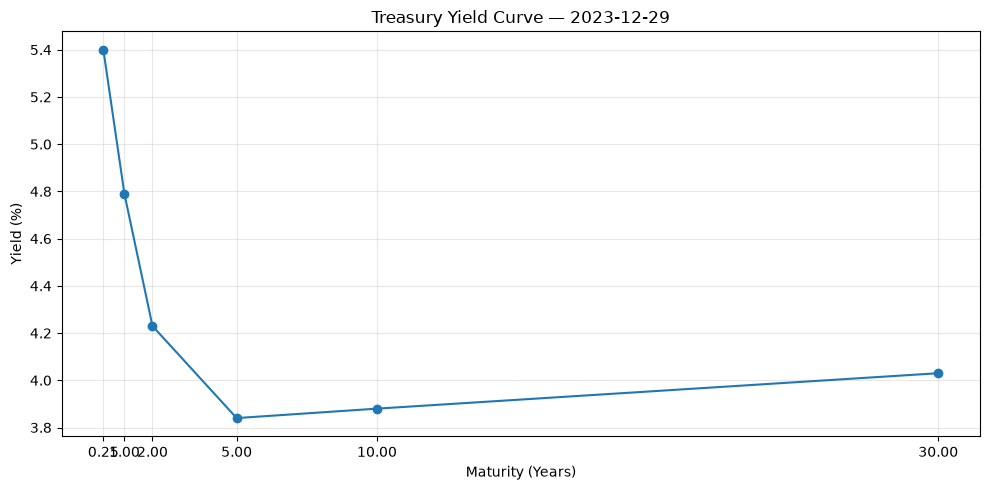

In [6]:
latest_yields = yields.iloc[-1]
maturities = np.array([0.25, 1, 2, 5, 10, 30])

plt.figure(figsize=(10,5))

plt.plot(
    maturities,
    latest_yields,
    marker = 'o'
)

plt.title(f"Treasury Yield Curve — {yields.index[-1].date()}")
plt.xlabel("Maturity (Years)")
plt.ylabel("Yield (%)")
plt.xticks(maturities)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 9. Bond Pricing and Cash Flows

A fixed-coupon bond pays periodic coupons and repays principal at maturity. Under a regular coupon schedule, its theoretical value is the present value of all future coupons and principal discounted at the yield to maturity (YTM).

For face value \(F\), annual coupon rate \(c\), annual YTM \(y\), maturity \(T\), and coupon frequency \(m\), the regular-payment formula is

$$
P=\sum_{k=1}^{Tm}\frac{Fc/m}{(1+y/m)^k}+\frac{F}{(1+y/m)^{Tm} }.
$$

This implementation assumes an integer number of regular coupon periods and a nominal annual YTM compounded at the coupon frequency. It does not model settlement dates, accrued interest, day-count conventions, holidays, or the distinction between clean and dirty prices. The calculated price is the present value for the **face value passed to the function**; when face value is $1,000,000, the return is the value of that whole position, not a quoted price per $100 of face value.


In [7]:
face_value = 1000
coupon_rate = 0.05
maturity_years = 5
ytm = 0.04
coupon_frequency = 2

### 9.1 Implementing the Bond Pricing Function

The function below discounts each coupon payment and the final principal payment. The `coupon_frequency` parameter defaults to semiannual payments, matching the simplified convention used throughout the portfolio analysis.

The function is intentionally a regular-coupon pricing model. Its output scales with `face_value`, so downstream portfolio calculations must not multiply the returned price by face value a second time.


In [8]:
def bond_price(
    face_value,
    coupon_rate,
    maturity_years,
    ytm,
    coupon_frequency=2
):
    periods = maturity_years * coupon_frequency
    coupon_payment = face_value * coupon_rate / coupon_frequency
    periodic_yield = ytm / coupon_frequency

    coupon_periods = np.arange(1, periods + 1)

    coupon_pv = np.sum(
        coupon_payment / (1 + periodic_yield) ** coupon_periods
    )

    principal_pv = (
        face_value / (1 + periodic_yield) ** periods
    )

    return coupon_pv + principal_pv

In [9]:
price = bond_price(
    face_value,
    coupon_rate,
    maturity_years,
    ytm,
    coupon_frequency
)

print(f"Bond price: {price:.2f}")

Bond price: 1044.91


## 10. Interest-Rate Risk Measurement

A bond's price-yield relationship is nonlinear. Duration gives a first-order sensitivity estimate, while convexity improves the approximation for larger yield changes.

The function below calculates:

- **Macaulay duration:** present-value-weighted average time to receive the cash flows.
- **Modified duration:** approximate percentage price sensitivity to a unit change in yield under the stated compounding convention.
- **DV01:** approximate dollar price change for a 1-basis-point (0.01 percentage-point) yield change. It is reported as a positive risk magnitude; the price change for a yield increase is approximately negative DV01.
- **Convexity:** second-order curvature of the price-yield relationship under the same coupon-frequency convention.

Because the price uses the supplied face value, DV01 also scales to that face value. For a portfolio position, these dollar DV01 values can be aggregated when the same parallel 1 bp shock is applied to every bond yield.


In [10]:
def bond_risk_measures(
        face_value,
        coupon_rate,
        maturity_years,
        ytm,
        coupon_frequency = 2
):
    periods = int(maturity_years * coupon_frequency)
    coupon = face_value * coupon_rate / coupon_frequency
    periodic_yield = ytm / coupon_frequency

    times = np.arange(1, periods + 1) / coupon_frequency

    cash_flows = np.full(periods, coupon)
    cash_flows[-1] = cash_flows[-1] + face_value

    discount_factors = (1+periodic_yield)**np.arange(1, periods + 1)
    present_values = cash_flows/discount_factors

    price = present_values.sum()

    macaulay_duration = np.sum(times*present_values)/ price
    modified_duration = macaulay_duration / (1 + periodic_yield)

    dv01 = price * modified_duration * 0.0001

    convexity = np.sum(
        present_values * np.arange(1, periods+1)* (np.arange (1, periods+1) + 1)
    )/ (price * coupon_frequency**2 * (1+periodic_yield)**2)


    return {
        "price": price,
        "macaulay_duration": macaulay_duration,
        "modified_duration": modified_duration,
        "dv01": dv01,
        "convexity": convexity
    }


## 11. Bond Price Sensitivity and Yield-Shock Analysis

Duration and convexity approximate the effect of a yield change on price. Full repricing recalculates the present value of all cash flows at the shocked yield and serves as the benchmark under this bond-pricing model.

The comparison reports price estimates under negative and positive shocks. Smaller shocks should generally be approximated closely by duration; adding convexity typically improves the approximation for larger shocks. The error is measured in currency units per bond or position, depending on the `face_value` passed to the function.


In [11]:
def compare_yield_shocks(
        face_value,
        coupon_rate,
        maturity_years,
        ytm,
        coupon_frequency = 2,
        shocks_bps = (-200, -100, -50, -25, 25, 50, 100, 200)
):
    risk = bond_risk_measures( face_value,coupon_rate, maturity_years, ytm, coupon_frequency)
    base_price = risk['price']
    duration = risk['modified_duration']
    convexity = risk['convexity']

    results = []

    for shock in shocks_bps:
        delta_y = shock / 10_000
        shocked_yield = ytm + delta_y

        shocked_price = bond_price(face_value, coupon_rate, maturity_years, shocked_yield, coupon_frequency)

        duration_change = -duration * delta_y
        convexity_change = 0.5 * convexity * delta_y **2
        duration_convexity_price = (1 + duration_change + convexity_change) * base_price

        results.append({
            "Shock (bps)" : shock,
            "Shocked Yield (%)" : shocked_yield*100,
            "Full Repricing" : shocked_price,
            "Duration Estimate" : base_price * (1+duration_change),
            "Duration + Convexity Estimate " : duration_convexity_price,
            "Difference (Approx vs Full)" : duration_convexity_price - shocked_price
        })

    return pd.DataFrame(results).set_index("Shock (bps)")

In [12]:
shock_results = compare_yield_shocks(
    face_value,
    coupon_rate,
    maturity_years,
    ytm,
    coupon_frequency
)

shock_results

,Shocked Yield (%),Full Repricing,Duration Estimate,Duration + Convexity Estimate,Difference (Approx vs Full)
Shock (bps),,,,,
-200,2.00,1142.069568,1137.088662,1141.879200,-0.190368
-100,3.00,1092.221846,1091.000793,1092.198428,-0.023418
-50,3.50,1068.259172,1067.956859,1068.256268,-0.002904
-25,3.75,1056.510106,1056.434892,1056.509744,-0.000362
25,4.25,1033.465451,1033.390958,1033.465810,0.000359
50,4.50,1022.165541,1021.868991,1022.168400,0.002859
100,5.00,1000.000000,998.825057,1000.022691,0.022691
200,6.00,957.348986,952.737188,957.527727,0.178741


## 12. Finite-Difference Duration and the Difference from Key Rate Duration

This section estimates duration numerically using a central finite difference. It reprices the **same bond** after bumping its single YTM input up and down by one basis point:

$$
D_{\mathrm{FD}}\approx\frac{P(y-\Delta y)-P(y+\Delta y)}{2P_0\Delta y}.
$$

Here, \(P_0\) is the base price and \(\Delta y\) is the decimal yield bump. This is a numerical estimate of modified duration and should be close to the analytical modified duration calculated earlier.

**This is not genuine key rate duration (KRD).** KRD requires a curve-based valuation framework and separately shocks one selected maturity node while holding the other curve nodes fixed. The current bond pricer takes one YTM rather than a full discount curve, so it cannot isolate individual curve-node sensitivities. That extension is outside the current implementation.


In [13]:
def finite_difference_duration(
        face_value,
        coupon_rate,
        maturity_years,
        ytm,
        coupon_frequency = 2,
        bump_bps = 1
):
    bump = bump_bps / 10_000

    base_price = bond_price(face_value, coupon_rate, maturity_years, ytm, coupon_frequency)

    price_down = bond_price(face_value, coupon_rate, maturity_years, ytm - bump, coupon_frequency)

    price_up = bond_price(face_value, coupon_rate, maturity_years, ytm + bump, coupon_frequency)

    return (price_down - price_up)/(2 * base_price * bump)


In [14]:
risk = bond_risk_measures(face_value, coupon_rate, maturity_years, ytm, coupon_frequency)

finite_diff_duration = finite_difference_duration(face_value, coupon_rate, maturity_years, ytm, coupon_frequency)

pd.Series({
    "Modified Duration" : risk['modified_duration'],
    "Finite-Difference Duration" : finite_diff_duration
})


Modified Duration             4.41069
Finite-Difference Duration    4.41069
dtype: float64

**Interpretation of the output:** the finite-difference duration should be close to the modified duration above. The equality in this single-YTM illustration is expected: both measure sensitivity to a parallel change in that one yield input. It does not provide separate 2Y, 5Y, 10Y, or 30Y curve-node risk; that requires a term-structure pricer and genuine key rate duration calculations.


## 13. Par-Yield Curve Interpolation

The input series contains observed par yields at six maturities. Linear interpolation provides estimated par yields between those observed tenors and is useful for plotting and constructing approximate curve scenarios.

Interpolation does not turn par yields into zero-coupon spot rates. It also does not add new market information: values between observed maturities are model-generated estimates. The function converts the input yields from percentage points into decimal yields internally; the plot converts them back to percentage points for display.


In [15]:
def interpolate_yield_curve( yield_curve, target_maturities, key_maturities = np.array([0.25, 1, 2, 5, 10, 30])):
    observed_yields = yield_curve.to_numpy(dtype = float) / 100

    return np.interp(
        target_maturities,
        key_maturities,
        observed_yields
    )

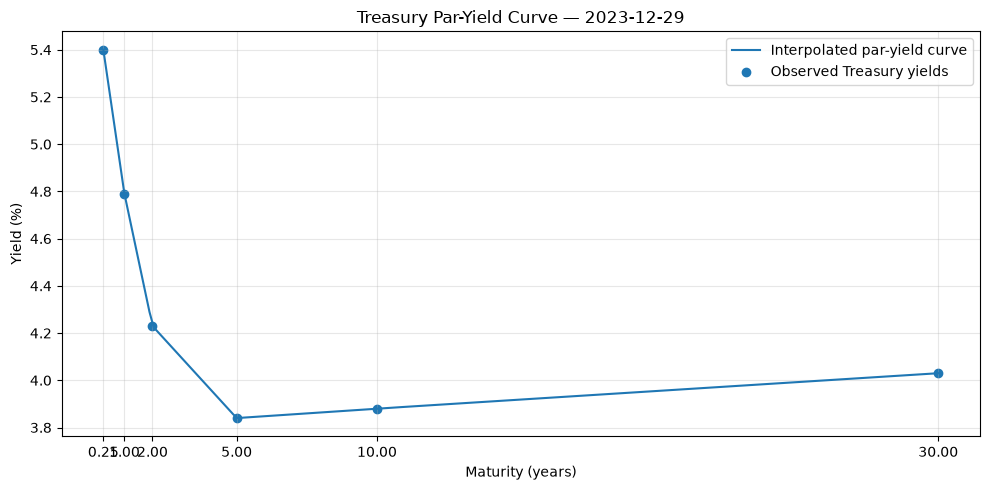

In [16]:
latest_curve = yields.iloc[-1]
target_maturities = np.linspace(0.25, 30, 200)

interpolated_yields = interpolate_yield_curve(
    latest_curve,
    target_maturities
)

plt.figure(figsize=(10, 5))
plt.plot(
    target_maturities,
    interpolated_yields * 100,
    label="Interpolated par-yield curve"
)
plt.scatter(
    np.array([0.25, 1, 2, 5, 10, 30]),
    latest_curve.values,
    label="Observed Treasury yields"
)
plt.title(f"Treasury Par-Yield Curve — {yields.index[-1].date()}")
plt.xlabel("Maturity (years)")
plt.ylabel("Yield (%)")
plt.legend()
plt.xticks(np.array([0.25, 1, 2, 5, 10, 30]))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 14. Approximate Spot-Curve Bootstrap

A **par yield** is the coupon rate that makes a hypothetical coupon bond trade at par. A **spot rate** is the yield used to discount a single cash flow at a particular maturity. Discount factors can be bootstrapped sequentially from par instruments, then converted to spot rates.

The current implementation is an **educational approximation**, not a market-calibrated Treasury zero-coupon curve. It uses the six observed par-yield points, linearly interpolates them to semiannual coupon dates, assumes each interpolated par yield is the coupon rate of a hypothetical par-priced semiannual bond, and bootstraps a discount factor at each six-month node.

For a par bond with coupon per period \(q\), the final discount factor at that node is calculated as

$$
DF_n=\frac{1-q\sum_{i=1}^{n-1}DF_i}{1+q},
$$

where the par bond price is normalized to 1. The spot rates are then calculated using nominal annual rates with semiannual compounding.

**Limitations:** the observed 3M bill is not itself bootstrapped as a 3-month discount factor; it influences the interpolated par yield used at the first six-month node. Intermediate par yields are interpolated rather than observed, and actual Treasury instruments, settlement conventions, and instrument-specific cash flows are not used. The resulting curve is suitable for demonstrating the method, not for production pricing or precise risk attribution.


In [17]:
def bootstrap_discount_curve(par_yields, maturities, frequency=2):
    par_yields = np.asarray(par_yields, dtype=float)
    maturities = np.asarray(maturities, dtype=float)

    # Inputs are decimal annual par yields and maturities in years.
    # Sort maturity points
    order = np.argsort(maturities)
    maturities = maturities[order]
    par_yields = par_yields[order]

    # Interpolate the sparse par-yield observations to semiannual coupon dates.
    # This makes the bootstrap internally consistent with the assumed coupon frequency.
    # Bootstrap at every coupon date
    coupon_dates = np.arange(1 / frequency, maturities[-1] + 1e-9, 1 / frequency)

    interpolated_yields = np.interp(
        coupon_dates, maturities, par_yields
    )

    discount_factors = []

    for i, y in enumerate(interpolated_yields):
        coupon = y / frequency

        # The par bond pays coupon * DF at each prior coupon date.
        # Present value of coupons before the final payment
        coupon_pv = coupon * sum(discount_factors)

        # Par bond price = 1
        df = (1 - coupon_pv) / (1 + coupon)
        discount_factors.append(df)

    discount_factors = np.array(discount_factors)

    # Convert discount factors to nominal annual spot rates with `frequency` compounding.
    spot_rates = frequency * (
        discount_factors ** (-1 / (coupon_dates * frequency)) - 1
    )

    return pd.DataFrame({
        "Par Yield (%)": interpolated_yields * 100,
        "Discount Factor": discount_factors,
        "Spot Rate (%)": spot_rates * 100
    }, index=coupon_dates)


In [18]:
key_maturities = np.array([0.25, 1, 2, 5, 10, 30])

latest_curve = yields.iloc[-1]

spot_curve = bootstrap_discount_curve(
    latest_curve.values / 100,
    key_maturities
)

spot_curve.index.name = "Maturity (Years)"
spot_curve.round(4).head(10)

,Par Yield (%),Discount Factor,Spot Rate (%)
Maturity (Years),,,
0.5,5.1967,0.9747,5.1967
1.0,4.7900,0.9538,4.7851
1.5,4.5100,0.9354,4.5006
2.0,4.2300,0.9200,4.2144
2.5,4.1650,0.9024,4.1500
3.0,4.1000,0.8858,4.0843
3.5,4.0350,0.8700,4.0177
4.0,3.9700,0.8551,3.9505
4.5,3.9050,0.8411,3.8827


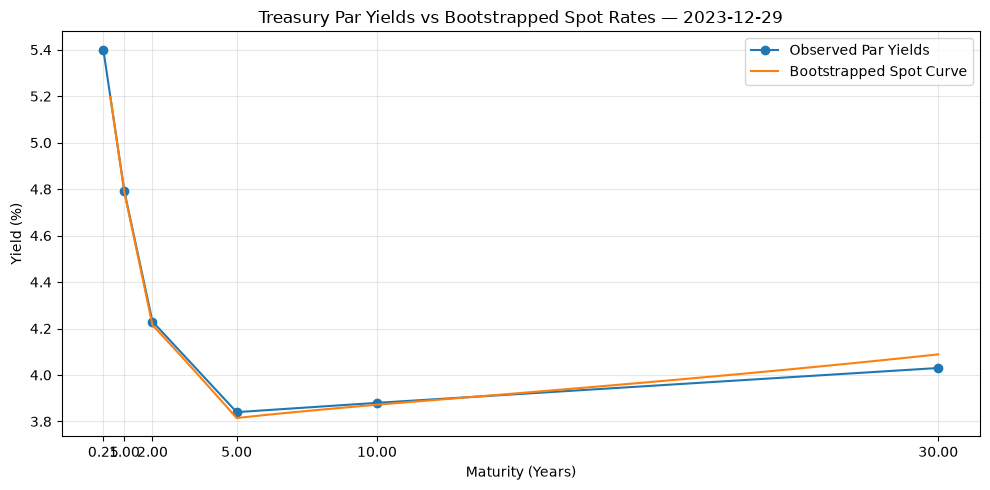

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    key_maturities,
    latest_curve.values,
    marker="o",
    label="Observed Par Yields"
)

plt.plot(
    spot_curve.index,
    spot_curve["Spot Rate (%)"],
    label="Bootstrapped Spot Curve"
)

plt.title(f"Treasury Par Yields vs Bootstrapped Spot Rates — {yields.index[-1].date()}")
plt.xlabel("Maturity (Years)")
plt.ylabel("Yield (%)")
plt.xticks(key_maturities)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Historical Yield-Curve Changes and PCA

Principal Component Analysis (PCA) summarizes correlated changes in the six Treasury par-yield series using a smaller number of orthogonal statistical factors.

We calculate daily changes in basis points, standardize the changes at each maturity, and fit PCA to the standardized observations. Standardization means the factors describe patterns in **standard-deviation units**, not directly in basis points or dollar portfolio P&L.

The first three components will be inspected for level-like, slope-like, and curvature-like patterns. These are economic interpretations of the loading shapes, not guaranteed labels. In this notebook PCA is exploratory; its factors are not yet used to price the portfolio or calculate PCA-based VaR.


In [20]:
# Yields are stored in percentage points: a 0.01 percentage-point change is 1 bp.
yield_changes = yields.diff().dropna() * 100
yield_changes.head()


,3M,1Y,2Y,5Y,10Y,30Y
date,,,,,,
2010-01-05,-1.0,-4.0,-8.0,-9.0,-8.0,-6.0
2010-01-06,-1.0,-1.0,0.0,4.0,8.0,11.0
2010-01-07,-1.0,0.0,2.0,2.0,0.0,-1.0
2010-01-08,0.0,-3.0,-7.0,-5.0,-2.0,1.0
2010-01-11,-1.0,-2.0,-1.0,1.0,2.0,4.0


In [21]:
from sklearn.preprocessing import StandardScaler

# Standardize each maturity so the PCA is not dominated solely by its raw volatility.
scaler = StandardScaler()

scaled_changes = scaler.fit_transform(yield_changes)

pca = PCA()
pca.fit(scaled_changes)

explained_variance = pd.Series(
    pca.explained_variance_ratio_ * 100,
    index = [f"PC{i+1}" for i in range(len(yields.columns))],
    name = "Explained Variance (%)"
)

explained_variance


PC1    65.604182
PC2    18.667676
PC3    10.710433
PC4     3.432359
PC5     1.263269
PC6     0.322081
Name: Explained Variance (%), dtype: float64

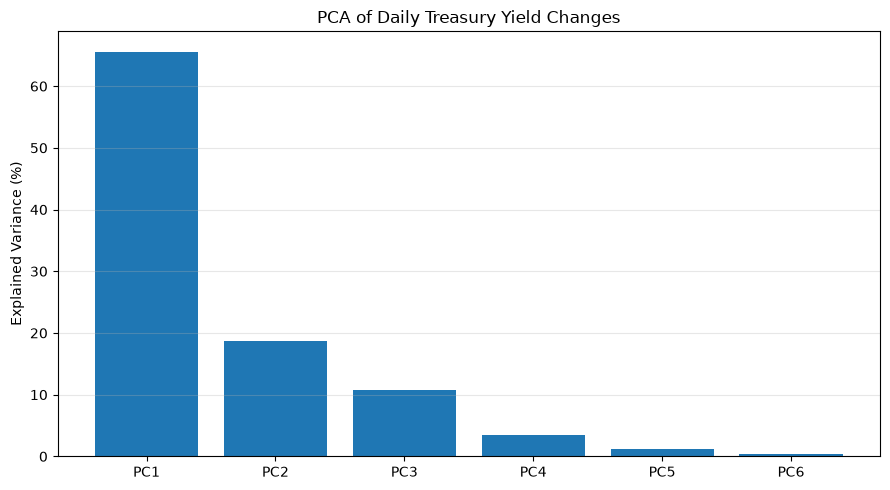

In [22]:
plt.figure(figsize=(9, 5))

plt.bar(
    explained_variance.index,
    explained_variance.values
)

plt.ylabel("Explained Variance (%)")
plt.title("PCA of Daily Treasury Yield Changes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
pca_loadings = pd.DataFrame(
    pca.components_[:3].T,
    index=yields.columns,
    columns=["PC1", "PC2", "PC3"]
)

pca_loadings.round(3)

,PC1,PC2,PC3
3M,0.204,0.695,0.673
1Y,0.376,0.452,-0.437
2Y,0.448,0.164,-0.406
5Y,0.480,-0.152,-0.076
10Y,0.465,-0.315,0.185
30Y,0.411,-0.403,0.389


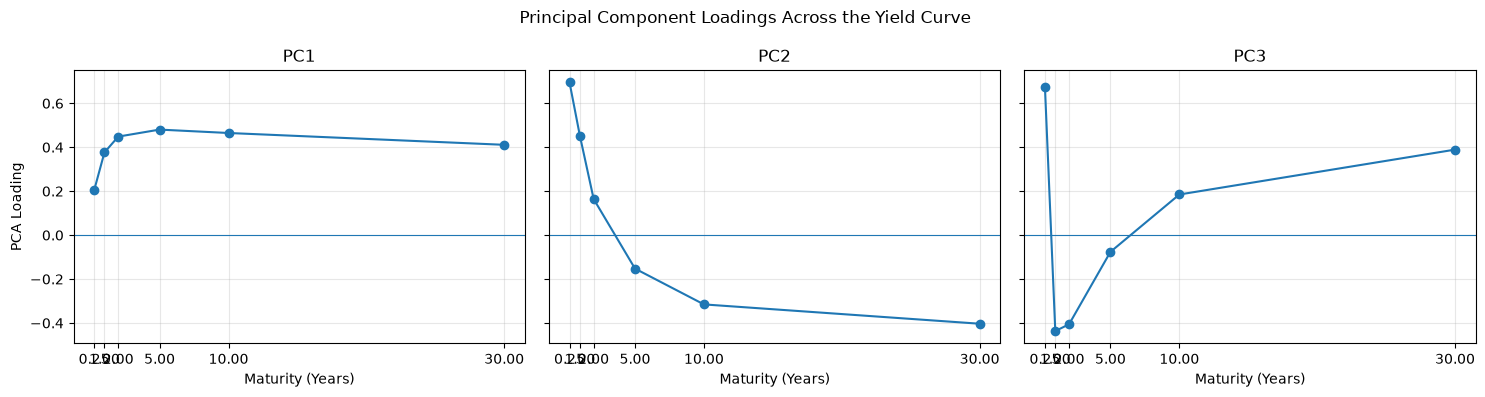

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for i, component in enumerate(["PC1", "PC2", "PC3"]):
    axes[i].plot(
        key_maturities,
        pca_loadings[component],
        marker="o"
    )
    axes[i].axhline(0, linewidth=0.8)
    axes[i].set_title(component)
    axes[i].set_xlabel("Maturity (Years)")
    axes[i].set_xticks(key_maturities)
    axes[i].grid(True, alpha=0.3)

axes[0].set_ylabel("PCA Loading")
plt.suptitle("Principal Component Loadings Across the Yield Curve")
plt.tight_layout()
plt.show()

In [25]:
cumulative_variance = explained_variance.cumsum()

variance_summary = pd.DataFrame({
    "Explained Variance (%)": explained_variance,
    "Cumulative Variance (%)": cumulative_variance
})

variance_summary.round(2)

,Explained Variance (%),Cumulative Variance (%)
PC1,65.60,65.60
PC2,18.67,84.27
PC3,10.71,94.98
PC4,3.43,98.41
PC5,1.26,99.68
PC6,0.32,100.00


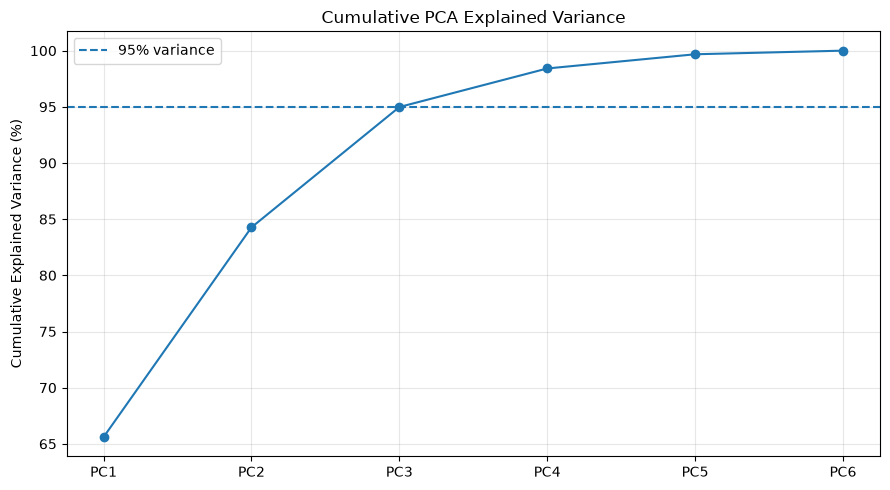

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(
    cumulative_variance.index,
    cumulative_variance.values,
    marker="o"
)

plt.axhline(95, linestyle="--", label="95% variance")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative PCA Explained Variance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 15.1 PCA Results: Explained Variance and Factor Shape

In the current sample, the first three components explain approximately **94.98%** of the variation in standardized daily yield changes; the fourth raises the cumulative total to approximately **98.41%**. The first component has positive loadings across all maturities and is therefore level-like. The second contrasts short and long maturities and is slope-like. The third has a mixed loading shape, so its interpretation as curvature is less clean.

These labels are qualitative interpretations of the estimated loadings. Because the input changes were standardized by maturity, the PCA factors should not be read directly as basis-point shocks or dollar portfolio sensitivities. The PCA is descriptive here; it is not yet connected to the portfolio VaR calculation.


## 16. Synthetic Treasury Portfolio Construction and Risk

We create an illustrative portfolio with one position at each of four maturities: 2Y, 5Y, 10Y, and 30Y. Each position has $1,000,000 face value. Coupon rates are assumptions; the YTMs are set to the corresponding latest observed par yields in the CSV (December 29, 2023).

For each bond, the notebook calculates the present value of the position's cash flows, modified duration, and DV01. Because `bond_risk_measures()` receives the full face value, the returned `Price` is the **market value of that whole position**, not a quoted price per $100 face value. The table will label this amount as `Market Value` to avoid confusion.

Portfolio modified duration is the market-value-weighted average of individual modified durations. Total DV01 is the sum of position-level dollar DV01 values and approximates the portfolio loss from a 1 bp parallel rise in the four bond yields.


In [27]:
portfolio = pd.DataFrame({
    "Maturity": [2, 5, 10, 30],
    "Coupon Rate": [0.04, 0.04, 0.04, 0.045],
    "YTM": [0.0423, 0.0384, 0.0388, 0.0403],
    "Face Value": [1_000_000] * 4
})

portfolio

,Maturity,Coupon Rate,YTM,Face Value
0,2,0.040,0.0423,1000000
1,5,0.040,0.0384,1000000
2,10,0.040,0.0388,1000000
3,30,0.045,0.0403,1000000


In [28]:
risk_rows = []

for _, bond in portfolio.iterrows():
    risk = bond_risk_measures(
        face_value=bond["Face Value"],
        coupon_rate=bond["Coupon Rate"],
        maturity_years=bond["Maturity"],
        ytm=bond["YTM"],
        coupon_frequency=2
    )

    risk_rows.append({
        **bond.to_dict(),
        "Market Value": risk["price"],
        "Modified Duration": risk["modified_duration"],
        "DV01": risk["dv01"]
    })

portfolio_risk = pd.DataFrame(risk_rows)

portfolio_risk[
    ["Maturity", "Coupon Rate", "YTM", "Face Value",
     "Market Value", "Modified Duration", "DV01"]
].round(2)


,Maturity,Coupon Rate,YTM,Face Value,Market Value,Modified Duration,DV01
0,2.0,0.04,0.04,1000000.0,995633.30,1.90,189.33
1,5.0,0.04,0.04,1000000.0,1007216.24,4.50,452.91
2,10.0,0.04,0.04,1000000.0,1009867.90,8.19,827.10
3,30.0,0.04,0.04,1000000.0,1081392.22,16.92,1830.10


In [29]:
total_market_value = portfolio_risk["Market Value"].sum()

portfolio_duration = (portfolio_risk["Market Value"] * portfolio_risk["Modified Duration"]).sum() / total_market_value

total_dv01 = portfolio_risk["DV01"].sum()

print(f"Total Market Value: ${total_market_value:,.2f}")
print(f"Portfolio Modified Duration: {portfolio_duration:.2f} years")
print(f"Portfolio DV01: ${total_dv01:,.2f} per bp")


Total Market Value: $4,094,109.67
Portfolio Modified Duration: 8.06 years
Portfolio DV01: $3,299.44 per bp


## 17. Historical Yield-Change Scenario P&L, VaR, and Expected Shortfall

This section constructs a distribution of portfolio P&L by applying each observed daily yield change to the **fixed reference yields** in the synthetic portfolio and fully repricing all four bond positions.

For each historical date in the yield-change dataset:

1. Apply the observed 2Y, 5Y, 10Y, and 30Y changes to the corresponding bond's reference YTM.
2. Reprice the bond using its fixed coupon, maturity, and face value.
3. Subtract the base position value and sum the four position P&Ls.
4. Estimate historical VaR and Expected Shortfall from the resulting scenario P&L distribution.

The 3M and 1Y series remain in the dataset for yield-curve exploration and PCA, but they do not directly shock this four-bond portfolio because it has no positions at those maturities.

**Interpretation caveat:** these are historical yield-change **scenario P&Ls for today's fixed reference portfolio assumptions**, not actual realized daily P&L for a portfolio that was revalued at each historical date with its then-current market yields and holdings. VaR estimates are conditional on this scenario construction and the chosen historical sample.


In [30]:
yield_changes

,3M,1Y,2Y,5Y,10Y,30Y
date,,,,,,
2010-01-05,-1.0,-4.0,-8.0,-9.0,-8.0,-6.0
2010-01-06,-1.0,-1.0,0.0,4.0,8.0,11.0
2010-01-07,-1.0,0.0,2.0,2.0,0.0,-1.0
2010-01-08,0.0,-3.0,-7.0,-5.0,-2.0,1.0
2010-01-11,-1.0,-2.0,-1.0,1.0,2.0,4.0
...,...,...,...,...,...,...
2023-12-22,2.0,-2.0,-2.0,0.0,1.0,2.0
2023-12-26,1.0,1.0,-5.0,2.0,-1.0,-1.0
2023-12-27,-1.0,-4.0,-6.0,-11.0,-10.0,-9.0


### 17.1 Constructing the Scenario P&L Series

The table above shows the aligned daily changes at all six maturities, measured in basis points. The next cell uses only the maturities represented in the portfolio (2Y, 5Y, 10Y, and 30Y). Each historical vector is applied to the fixed reference YTM for each position, and the price difference is aggregated across positions. This creates a consistent scenario distribution, but it should not be described as realized historical portfolio returns.


In [31]:
portfolio_maturities = {
    2: "2Y",
    5: "5Y",
    10: "10Y",
    30: "30Y"
}

historical_pnl = []

for date, changes in yield_changes.iterrows():
    daily_pnl = 0

    for _, bond in portfolio.iterrows():
        maturity = bond["Maturity"]
        yield_column = portfolio_maturities[int(maturity)]

        shocked_yield = bond["YTM"] + changes[yield_column] / 10_000

        shocked_price = bond_price(
            bond["Face Value"],
            bond["Coupon Rate"],
            maturity,
            shocked_yield,
            coupon_frequency=2
        )

        base_price = bond_price(
            bond["Face Value"],
            bond["Coupon Rate"],
            maturity,
            bond["YTM"],
            coupon_frequency=2
        )

        daily_pnl += shocked_price - base_price

    historical_pnl.append(daily_pnl)

historical_pnl = pd.Series(
    historical_pnl,
    index=yield_changes.index,
    name="Portfolio P&L"
)

historical_pnl.describe().round(2)

count     3501.00
mean        74.93
std      16458.58
min     -84683.33
25%      -9873.86
50%        285.33
75%       9843.02
max      97917.47
Name: Portfolio P&L, dtype: float64

In [32]:
def historical_var_es(pnl, confidence_level=0.95):
    losses = -pnl

    var = losses.quantile(confidence_level)
    expected_shortfall = losses[losses >= var].mean()

    return {
        "Confidence Level": confidence_level,
        "Historical VaR ($)": var,
        "Expected Shortfall ($)": expected_shortfall
    }

risk_95 = historical_var_es(historical_pnl, 0.95)
risk_99 = historical_var_es(historical_pnl, 0.99)

historical_var = pd.DataFrame([risk_95, risk_99]).set_index(
    "Confidence Level"
).round(2)

historical_var

,Historical VaR ($),Expected Shortfall ($)
Confidence Level,,
0.95,26159.21,35421.25
0.99,40475.88,50234.96


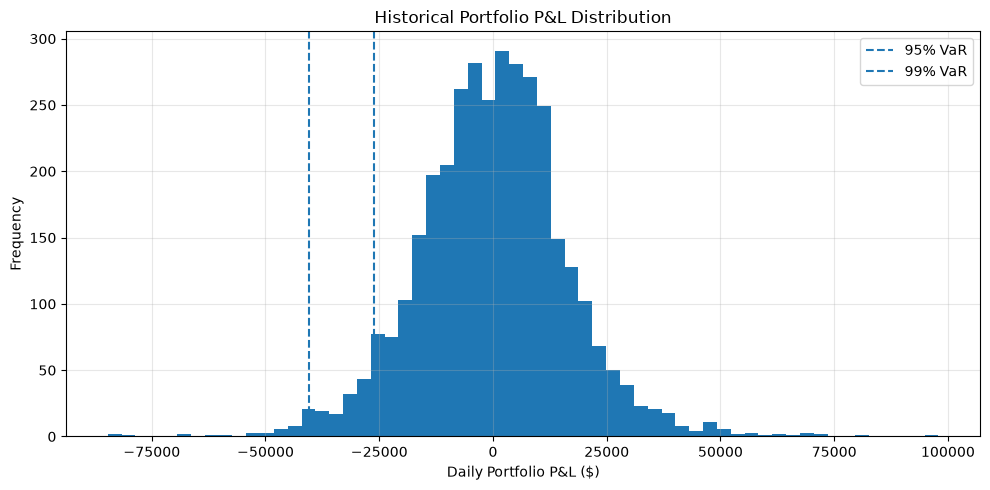

In [33]:
plt.figure(figsize=(10, 5))

plt.hist(historical_pnl, bins=60)

plt.axvline(
    -risk_95["Historical VaR ($)"],
    linestyle="--",
    label="95% VaR"
)

plt.axvline(
    -risk_99["Historical VaR ($)"],
    linestyle="--",
    label="99% VaR"
)

plt.xlabel("Daily Portfolio P&L ($)")
plt.ylabel("Frequency")
plt.title("Historical Portfolio P&L Distribution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 18. Rolling Historical VaR Exception Analysis

A rolling window separates the observations used to estimate each VaR threshold from the next observation used to test it. With a 500-observation window, the first 500 scenario P&Ls estimate the VaR threshold for the next scenario; the window then advances one observation at a time.

For each 95% and 99% threshold, an **exception** occurs when the next scenario loss exceeds the VaR forecast. The observed exception rate is compared with the target rate (5% for 95% VaR and 1% for 99% VaR).

**Important qualification:** this is an out-of-sample-style rolling evaluation of the constructed historical scenario-P&L sequence. It is not a conventional backtest against independently observed daily P&L from a live or historically revalued portfolio, because the P&L series itself is generated by applying historical yield changes to a fixed reference portfolio. The later Kupiec test evaluates the exception frequency from this same rolling exercise.


In [34]:
def rolling_historical_var(pnl, window=500, confidence_levels=(0.95, 0.99)):
    losses = -pnl.dropna()
    results = []

    for i in range(window, len(losses)):
        historical_losses = losses.iloc[i - window:i]
        actual_loss = losses.iloc[i]

        row = {
            "Date": losses.index[i],
            "Actual Loss": actual_loss
        }

        for confidence in confidence_levels:
            var = historical_losses.quantile(confidence)
            row[f"VaR {confidence:.0%}"] = var
            row[f"Exception {confidence:.0%}"] = actual_loss > var

        results.append(row)

    return pd.DataFrame(results).set_index("Date")

oos_backtest = rolling_historical_var(historical_pnl, window=500)

summary = []

for confidence in (0.95, 0.99):
    exceptions = oos_backtest[f"Exception {confidence:.0%}"]

    summary.append({
        "Confidence Level": confidence,
        "Observations": len(exceptions),
        "Exceptions": int(exceptions.sum()),
        "Expected Exceptions (%)": (1 - confidence) * 100,
        "Actual Exceptions (%)": exceptions.mean() * 100
    })

pd.DataFrame(summary).set_index("Confidence Level").round(2)

,Observations,Exceptions,Expected Exceptions (%),Actual Exceptions (%)
Confidence Level,,,,
0.95,3001,161,5.0,5.36
0.99,3001,42,1.0,1.40


## 19. Parallel Yield-Curve Stress Testing

Parallel stress tests shift all four portfolio YTMs by the same number of basis points. Each shocked bond is fully repriced and the new position values are aggregated to obtain stressed portfolio value and P&L.

The scenarios apply shifts of +50, +100, and +200 bps and −50, −100, and −200 bps. Rising yields generally reduce fixed-coupon bond values; falling yields generally increase them. The response is nonlinear, so gains under yield declines need not be the exact mirror image of losses under equal-sized yield increases.

These are hypothetical sensitivities, not probability-weighted forecasts or estimates of a maximum possible loss.


In [35]:
stress_scenarios = {
    "Rates +200 bps": 0.02,
    "Rates +100 bps": 0.01,
    "Rates +50 bps": 0.005,
    "Rates -50 bps": -0.005,
    "Rates -100 bps": -0.01,
    "Rates -200 bps": -0.02
}

In [36]:
stress_results = []

for scenario, shock in stress_scenarios.items():
    stressed_value = 0

    for _, bond in portfolio.iterrows():
        stressed_yield = bond["YTM"] + shock

        if stressed_yield <= -2:
            raise ValueError("Invalid yield for semiannual bond pricing.")

        stressed_price = bond_price(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity_years=bond["Maturity"],
            ytm=stressed_yield,
            coupon_frequency=2
        )

        stressed_value += stressed_price

    stress_results.append({
        "Scenario": scenario,
        "Yield Shock (bps)": shock * 10_000,
        "Stressed Portfolio Value ($)": stressed_value,
        "P&L ($)": stressed_value - total_market_value
    })

stress_results = pd.DataFrame(stress_results).set_index("Scenario")
stress_results.round(2)

,Yield Shock (bps),Stressed Portfolio Value ($),P&L ($)
Scenario,,,
Rates +200 bps,200.0,3528202.24,-565907.42
Rates +100 bps,100.0,3789405.27,-304704.39
Rates +50 bps,50.0,3935687.95,-158421.72
Rates -50 bps,-50.0,4266163.58,172053.92
Rates -100 bps,-100.0,4453561.27,359451.60
Rates -200 bps,-200.0,4882539.74,788430.07


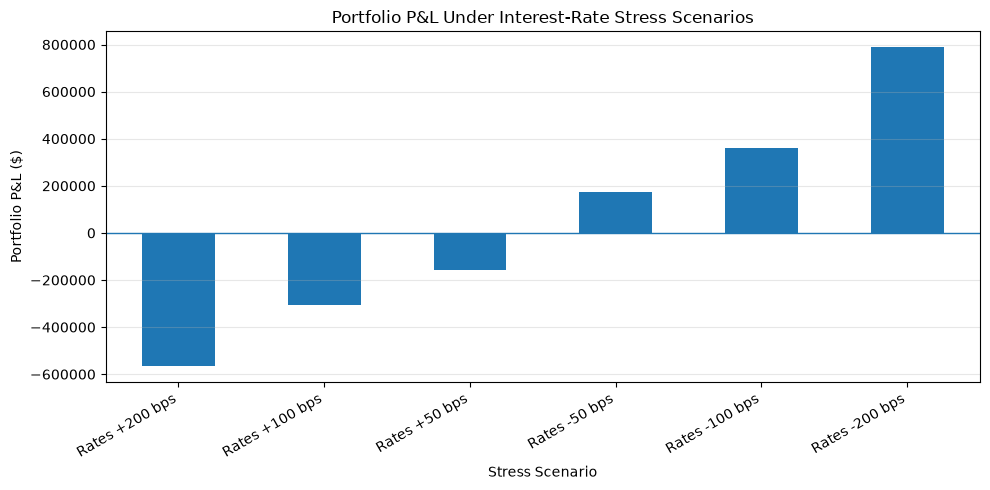

In [37]:
stress_results["P&L ($)"].sort_values().plot(
    kind="bar",
    figsize=(10, 5),
    title="Portfolio P&L Under Interest-Rate Stress Scenarios"
)

plt.axhline(0, linewidth=1)
plt.ylabel("Portfolio P&L ($)")
plt.xlabel("Stress Scenario")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 20. Non-Parallel Yield-Curve Stress Testing

Real yield curves rarely move in perfectly parallel fashion. This section applies maturity-specific shocks to the portfolio's 2Y, 5Y, 10Y, and 30Y yields to examine how curve-shape changes affect portfolio P&L.

- **Steepening scenario:** short yields fall while long yields rise.
- **Flattening scenario:** short yields rise while long yields fall.
- **Short-end shock:** the largest increases are concentrated at the short end.
- **Long-end shock:** the largest increases are concentrated at the long end.

These are defined illustrative scenarios, not fitted historical events. Full repricing reflects the nonlinear price-yield relationship for each bond, but the shocks remain stylized and do not constitute full curve-based key rate duration analysis.


In [38]:
curve_scenarios = {
    "Steepening": {2: -50, 5: 0, 10: 25, 30: 50},
    "Flattening": {2: 50, 5: 0, 10: -25, 30: -50},
    "Short-End Shock": {2: 100, 5: 50, 10: 25, 30: 25},
    "Long-End Shock": {2: 25, 5: 25, 10: 50, 30: 100}
}

In [39]:
curve_stress_results = []

for scenario, shocks in curve_scenarios.items():
    stressed_value = 0

    for _, bond in portfolio.iterrows():
        shock_bps = shocks[bond["Maturity"]]
        stressed_yield = bond["YTM"] + shock_bps / 10_000

        stressed_price = bond_price(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity_years=bond["Maturity"],
            ytm=stressed_yield,
            coupon_frequency=2
        )

        stressed_value += stressed_price

    curve_stress_results.append({
        "Scenario": scenario,
        "Stressed Portfolio Value ($)": stressed_value,
        "P&L ($)": stressed_value - total_market_value
    })

curve_stress_results = pd.DataFrame(curve_stress_results).set_index("Scenario")
curve_stress_results.round(2)

,Stressed Portfolio Value ($),P&L ($)
Scenario,,
Steepening,3996916.41,-97193.25
Flattening,4202843.69,108734.03
Short-End Shock,3988203.44,-105906.23
Long-End Shock,3874747.47,-219362.20


## 21. Consolidated Portfolio Risk Report

This summary combines several complementary risk views:

- **Market value:** current model value of the four synthetic bond positions.
- **Modified duration and DV01:** first-order interest-rate sensitivity under a parallel shift.
- **Historical VaR and Expected Shortfall:** tail-loss statistics from the constructed historical yield-change scenario P&Ls.
- **Stress P&L:** valuation impacts under selected parallel and non-parallel shocks.

These figures answer different questions and should not be treated as interchangeable. VaR and Expected Shortfall summarize a historical scenario distribution; stress tests show losses under specified shocks; duration and DV01 provide local sensitivity estimates. The report's results inherit the assumptions and limitations of the underlying pricing and scenario models.


In [40]:
risk_summary = {
    "Total Market Value ($)": total_market_value,
    "Portfolio Modified Duration (years)": portfolio_duration,
    "Portfolio DV01 ($/bp)": total_dv01,
    "Historical VaR 95% ($)": historical_var.loc[0.95, "Historical VaR ($)"],
    "Historical VaR 99% ($)": historical_var.loc[0.99, "Historical VaR ($)"],
    "Expected Shortfall 95% ($)": historical_var.loc[0.95, "Expected Shortfall ($)"],
    "Expected Shortfall 99% ($)": historical_var.loc[0.99, "Expected Shortfall ($)"],
    "Worst Parallel Stress P&L ($)": stress_results["P&L ($)"].min(),
    "Worst Curve Stress P&L ($)": curve_stress_results["P&L ($)"].min()
}

risk_summary_df = pd.Series(risk_summary, name="Value").to_frame()
risk_summary_df.round(2)

,Value
Total Market Value ($),4094109.67
Portfolio Modified Duration (years),8.06
Portfolio DV01 ($/bp),3299.44
Historical VaR 95% ($),26159.21
Historical VaR 99% ($),40475.88
Expected Shortfall 95% ($),35421.25
Expected Shortfall 99% ($),50234.96
Worst Parallel Stress P&L ($),-565907.42
Worst Curve Stress P&L ($),-219362.20


In [41]:
worst_parallel = stress_results["P&L ($)"].idxmin()
worst_curve = curve_stress_results["P&L ($)"].idxmin()

print(f"Worst parallel scenario: {worst_parallel}")
print(f"Worst parallel P&L: ${stress_results.loc[worst_parallel, 'P&L ($)']:,.2f}")

print(f"\nWorst curve scenario: {worst_curve}")
print(f"Worst curve P&L: ${curve_stress_results.loc[worst_curve, 'P&L ($)']:,.2f}")

Worst parallel scenario: Rates +200 bps
Worst parallel P&L: $-565,907.42

Worst curve scenario: Long-End Shock
Worst curve P&L: $-219,362.20


## 22. Kupiec Proportion-of-Failures (POF) Test

The Kupiec POF test assesses whether the observed out-of-sample-style VaR exception frequency is statistically consistent with the target exception probability. For a VaR confidence level \(c\), the null exception probability is \(p=1-c\).

The likelihood-ratio statistic compares:

- **Null hypothesis:** the exception probability equals the target rate \(1-c\).
- **Alternative hypothesis:** the exception probability differs from the target rate.

Under the null, the test statistic is asymptotically distributed as chi-squared with one degree of freedom. At a 5% significance level, a p-value below 0.05 leads to rejection of the null hypothesis of correct unconditional coverage.

The test considers only exception frequency; it does not test whether exceptions are independent or clustered. In this notebook, the exception flags come from the rolling VaR evaluation of fixed-reference scenario P&Ls, so the result should be interpreted as a diagnostic of that constructed series rather than validation against actual historical portfolio P&L.


In [42]:
from scipy.stats import chi2
from scipy.special import xlogy

def kupiec_pof_test(exceptions, confidence_level):
    exceptions = np.asarray(exceptions, dtype=bool)

    n = len(exceptions)
    x = exceptions.sum()

    expected_rate = 1 - confidence_level
    observed_rate = x / n

    log_likelihood_null = (
        xlogy(x, expected_rate)
        + xlogy(n - x, 1 - expected_rate)
    )

    log_likelihood_alternative = (
        xlogy(x, observed_rate)
        + xlogy(n - x, 1 - observed_rate)
    )

    lr_statistic = 2 * (
        log_likelihood_alternative - log_likelihood_null
    )

    p_value = chi2.sf(lr_statistic, df=1)

    return {
        "Observations": n,
        "Exceptions": int(x),
        "Expected Exception Rate (%)": expected_rate * 100,
        "Observed Exception Rate (%)": observed_rate * 100,
        "LR Statistic": lr_statistic,
        "P-value": p_value,
        "Reject at 5%": p_value < 0.05
    }


pof_results = {}

for confidence in (0.95, 0.99):
    exceptions = oos_backtest[f"Exception {confidence:.0%}"]

    pof_results[f"{confidence:.0%} VaR"] = kupiec_pof_test(
        exceptions,
        confidence
    )

pof_results = pd.DataFrame(pof_results).T
pof_results.round(4)

,Observations,Exceptions,Expected Exception Rate (%),Observed Exception Rate (%),LR Statistic,P-value,Reject at 5%
95% VaR,3001,161,5.0,5.364878,0.822436,0.364469,False
99% VaR,3001,42,1.0,1.399533,4.304126,0.03802,True


## 23. Final Findings, Interpretation, and Limitations

### Project Summary

This notebook implements an educational fixed-income analytics and market-risk workflow using historical US Treasury par yields from a local CSV. It covers regular-coupon bond pricing, duration and convexity, interpolation and an approximate spot-curve bootstrap, PCA of yield changes, an illustrative four-bond portfolio, historical yield-change scenario P&L, VaR and Expected Shortfall, rolling exception analysis, Kupiec POF testing, and stress testing.

### Key Findings

**1. Portfolio size and parallel-shift sensitivity**

The four synthetic positions have an aggregate market value of approximately **$4.094 million**. Their market-value-weighted modified duration is approximately **8.06 years**, and total DV01 is approximately **$3,299 per basis point**. As a first-order approximation, a parallel rise of 1 bp across all four bond yields would reduce portfolio value by about $3,299, before convexity and other effects.

**2. PCA of historical yield changes**

PCA was applied to standardized daily changes at 3M, 1Y, 2Y, 5Y, 10Y, and 30Y. In the current sample, PC1 explains about **65.60%**, PC2 **18.67%**, and PC3 **10.71%** of standardized variation. Together the first three components explain approximately **94.98%**; adding PC4 raises cumulative explained variance to approximately **98.41%**. The loading shapes are level-like, slope-like, and mixed/curvature-like, but they are statistical factors from standardized changes and are not directly dollar risk factors. PCA is exploratory in this notebook and is not used to generate portfolio VaR.

**3. Historical scenario VaR and Expected Shortfall**

Applying historical daily changes at the portfolio's four maturities to the fixed reference bond yields produced these estimates:

| Confidence level | Historical VaR | Expected Shortfall |
|---|---:|---:|
| 95% | $26,159 | $35,421 |
| 99% | $40,476 | $50,235 |

Expected Shortfall is larger than VaR at both confidence levels because it averages losses beyond the VaR threshold. These values describe the constructed scenario distribution, not a live portfolio forecast or realized historical performance.

**4. Parallel stress testing**

Among the parallel scenarios tested, a **+200 bp** shift produced the largest loss, approximately **$565,907**. A −200 bp shift produced an approximate gain of **$788,430**. This asymmetry is consistent with the nonlinear price-yield relationship and the positive convexity of the modeled fixed-coupon bonds. The selected scenarios are hypothetical and are not worst-case bounds.

**5. Non-parallel stress testing**

The largest loss among the defined curve-shape scenarios was approximately **$219,362** under the long-end shock. The steepening scenario produced a loss of approximately $97,193, while the flattening scenario produced a gain of approximately $108,734. The outcomes depend on the chosen maturity-specific shock sizes; they are not universal rankings of curve risks.

**6. Rolling VaR exception analysis and Kupiec test**

The rolling evaluation produced **3,001** test observations:

| Metric | 95% VaR | 99% VaR |
|---|---:|---:|
| Exceptions | 161 | 42 |
| Expected exception rate | 5.00% | 1.00% |
| Observed exception rate | 5.36% | 1.40% |
| Kupiec LR statistic | 0.8224 | 4.3041 |
| P-value | 0.3645 | 0.0380 |
| Reject target exception rate at 5%? | No | Yes |

At 95% confidence, the Kupiec test does not reject the null hypothesis that the exception rate equals 5%. At 99% confidence, the p-value of approximately 0.038 is below 0.05, so the null of a 1% exception rate is rejected. This indicates that the observed exception frequency is higher than the target rate in this evaluation.

This is a **rolling, out-of-sample-style diagnostic** for the scenario P&L series, not a conventional backtest on realized daily P&L from a portfolio revalued through time. The Kupiec test addresses unconditional exception frequency only; it does not test exception independence or clustering.

### Limitations and Scope Boundaries

1. **Synthetic portfolio:** The portfolio is illustrative, with fixed face-value positions and assumed coupons; it is not actual holdings or trades.
2. **Par yields versus spot rates:** The input data contain six par-yield tenors. The bootstrapped curve uses interpolated par yields and assumed semiannual par-bond cash flows; it is not calibrated to Treasury bills and coupon-bond prices and is not an official zero-coupon curve.
3. **Bond pricing conventions:** Pricing assumes regular coupon periods and a nominal YTM compounded at the coupon frequency. Settlement dates, accrued interest, clean/dirty price conventions, day counts, and irregular coupons are not modelled.
4. **Finite-difference duration versus KRD:** The notebook's central-difference function bumps a single bond YTM and reproduces modified duration. Genuine key rate duration—bumping one curve node at a time—is not implemented.
5. **Scenario P&L interpretation:** Historical yield changes are applied to fixed reference yields and fixed portfolio holdings. The resulting P&Ls are historical shock scenarios, not actual realized portfolio P&L at each historical date.
6. **VaR coverage evaluation:** The rolling window separates the observations used to estimate each threshold from the next scenario used to evaluate it, but this does not eliminate the fixed-reference scenario construction. The Kupiec test does not assess independence or conditional coverage.
7. **Method coverage:** The notebook does not yet implement parametric VaR, Monte Carlo VaR, PCA-based portfolio VaR, a hedge optimization, or a Christoffersen conditional-coverage test.

### Conclusion

The notebook demonstrates a connected workflow from bond cash-flow valuation to position-level sensitivity, portfolio risk aggregation, historical scenario analysis, and stress testing. The results illustrate why duration and DV01 are useful local measures but need to be complemented by full repricing and non-parallel stress scenarios.

The rolling exception analysis does not reject the 95% target rate, but it rejects the 99% target rate at the 5% significance level. This is a useful diagnostic, with the important caveat that the tested series is constructed from historical yield-change scenarios on a fixed reference portfolio. A stronger next step would use a time-varying portfolio valuation or genuinely observed historical P&L, add exception-independence/conditional-coverage testing, and implement actual curve-node KRD and market-calibrated discount factors.
